In [25]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import fashion_mnist
from sklearn.model_selection import train_test_split
from tensorflow import keras

In [26]:
(x_train_full, y_train_full), (x_test, y_test) = fashion_mnist.load_data()

print("Default Shape")
print(f"x_train_full shape: {x_train_full.shape}")
print(f"y_train_full shape: {y_train_full.shape}")
print(f"x_test shape: {x_test.shape}")
print(f"y_test shape: {y_test.shape}")

x_train, x_val, y_train, y_val = train_test_split(
    x_train_full,
    y_train_full,
    test_size=0.2,
    random_state=67,
    stratify=y_train_full
)

print("\nSplit Validation Set")
print(f"training set:    {x_train.shape},   label: {y_train.shape}")
print(f"validation set: {x_val.shape}, label: {y_val.shape}")
print(f"testing set:    {x_test.shape}, label: {y_test.shape}")

x_train = x_train.astype("float32")/255.0
x_val = x_val.astype("float32")/255.0
x_test = x_test.astype("float32")/255.0

print("\nค่าพิกเซลหลัง Normalisation")
print(f"min value: {x_train.min():.1f}, max value = {x_train.max():.1f}")

Default Shape
x_train_full shape: (60000, 28, 28)
y_train_full shape: (60000,)
x_test shape: (10000, 28, 28)
y_test shape: (10000,)

Split Validation Set
training set:    (48000, 28, 28),   label: (48000,)
validation set: (12000, 28, 28), label: (12000,)
testing set:    (10000, 28, 28), label: (10000,)

ค่าพิกเซลหลัง Normalisation
min value: 0.0, max value = 1.0


ป้อนเข้าโครงข่ายประสาทเทียมโดยตรงโดยไม่แปลงให้อยู่ในช่วง $[0.0, 1.0]$ จะก่อให้เกิดปัญหาต่อกระบวนการคำนวณ Gradient Descent และ Backpropagation
- การคำนวณ Gradient ผันผวนตามขนาด Input ($x$ สูงเกินไป) 
- ความชันของ Loss Landscape บิดเบี้ยว
- Sigmoid หรือ Softmax ค่าผลรวม z ที่สูงมากจะผลักให้ค่า Output เข้าสู่ขอบบนสุดของฟังก์ชัน ซึ่งบริเวณดังกล่าวมีค่าอนุพันธ์เข้าใกล้ 0 ทำให้เกิดปัญหา Vanishing Gradients
- ReLU ค่าผลลัพธ์ก็อาจพุ่งสูงจนทำให้เกิดปัญหา Dead ReLU ได้ง่ายขึ้น

In [27]:
model = keras.Sequential([
    keras.layers.Flatten(input_shape=(28, 28)),
    keras.layers.Dense(10, activation=tf.nn.softmax)
])

model.summary()

d:\GITHUB\DEEP-LEARNING\DEEP-LEARNING-Lecture-Work\dl_env\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_3 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         7,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,850 (30.66 KB)

 Trainable params: 7,850 (30.66 KB)

 Non-trainable params: 0 (0.00 B)

เลเยอร์ที่ 1: Flatten (0 พารามิเตอร์) ไม่มีการคูณค่าน้ำหนักหรือบวกค่าไบแอสใด ๆ จึงมีพารามิเตอร์เป็น 0 ตัว

เลเยอร์ที่ 2: Dense (7,850 พารามิเตอร์)
- จำนวนอินพุต ($N_{\text{in}}$): $784$ โหนด
- จำนวนเอาต์พุต ($N_{\text{out}}$): $10$ โหนด
- ค่าน้ำหนัก (Weights: $W$): $$\text{Weights} = N_{\text{in}} \times N_{\text{out}} = 784 \times 10 = 7,840 \text{ ตัว}$$
- ค่าไบแอส (Biases: $b$): $$\text{Biases} = N_{\text{out}} = 10 \text{ ตัว}$$

$$\begin{aligned} \text{Total Parameters} &= \text{Weights} + \text{Biases} \\ &= (784 \times 10) + 10 \\ &= 7,840 + 10 \\ &= 7,850 \text{ ตัว} \end{aligned}$$

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8626 - loss: 0.3958 - val_accuracy: 0.8567 - val_loss: 0.4237
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8644 - loss: 0.3913 - val_accuracy: 0.8546 - val_loss: 0.4240
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8656 - loss: 0.3881 - val_accuracy: 0.8572 - val_loss: 0.4271
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8654 - loss: 0.3862 - val_accuracy: 0.8588 - val_loss: 0.4179
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8660 - loss: 0.3845 - val_accuracy: 0.8580 - val_loss: 0.4217
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8667 - loss: 0.3829 - val_accuracy: 0.8530 - val_loss: 0.4321
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8683 - loss: 0.3793 - val_accuracy: 0.8541 - val_loss: 0.4350
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8679 - loss: 0.3792 - val_accuracy: 0.

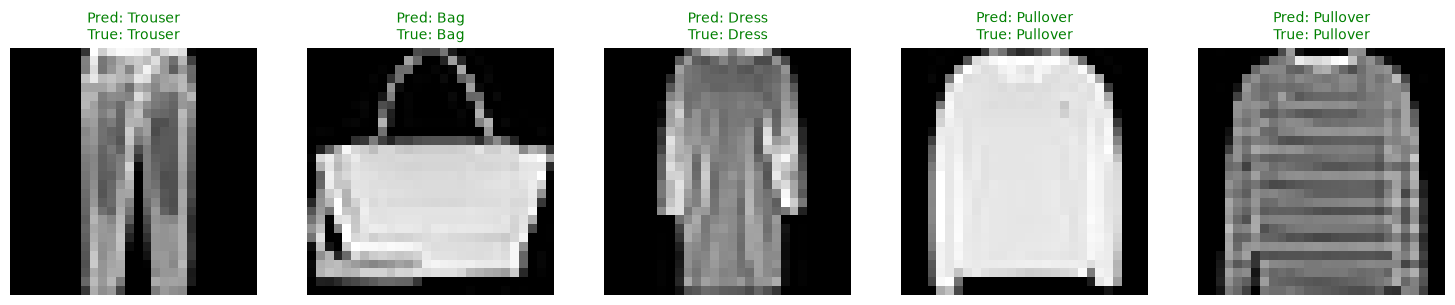

In [32]:
class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

model.compile(
    optimizer = keras.optimizers.Adam(),
    loss = 'sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    x_train,
    y_train,
    epochs=10,
    validation_data=(x_val, y_val),
    batch_size=64,
    verbose=1
)

predictions = model.predict(x_test)
predicted_classes = np.argmax(predictions, axis=1)

np.random.seed(67)
random_indices = np.random.choice(len(x_test), size=5, replace=False)

plt.figure(figsize=(15, 3))
for i, idx, in enumerate(random_indices):
    plt.subplot(1, 5, i + 1)
    plt.imshow(x_test[idx], cmap='gray')

    pred_label = class_names[predicted_classes[idx]]
    true_label = class_names[y_test[idx]]
    is_correct = (predicted_classes[idx] == y_test[idx])

    color = 'green' if is_correct else 'red'
    plt.title(f"Pred: {pred_label}\nTrue: {true_label}", color=color, fontsize=10)
    plt.axis('off')

plt.tight_layout()
plt.show()


- ทั้ง loss และ val_loss มีทิศทางลดลงสะท้อนว่าฟังก์ชันจุดประสงค์ (Cross-Entropy) ถูกปรับให้เข้าใกล้ศูนย์มากขึ้น ค่าคาดการณ์ของ Softmax ใกล้เคียงกับ Ground-truth One-Hot Vector มากขึ้น
- accuracy และ val_accuracy เพิ่มขึ้นจากประมาณ 79% ไปแตะระดับ 85–86% ซึ่งเป็นขีดจำกัดปกติของโมเดล Linear/Single-layer ที่ไม่มี Hidden Layer สำหรับจับความสัมพันธ์เชิงลึก
- ค่า val_loss และ val_accuracy เกาะกลุ่มใกล้เคียงกับชุดฝึกสอนตลอด 10 Epochs